<a href="https://colab.research.google.com/github/alrasyidinrafi-lab/data-mining-naive-bayes/blob/main/naive_bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Naive Bayes - Klasifikasi Survival Penumpang Titanic
**Mata Kuliah Data Mining - Pertemuan 5 (Latihan Soal / Kuis)**

Tujuan: memprediksi apakah penumpang Titanic selamat (`Survived` = 1) atau tidak (`Survived` = 0) menggunakan algoritma **Gaussian Naive Bayes**.

Tahapan mengikuti latihan sebelumnya (Social_Network_Ads), ditambah tahap *preprocessing* karena dataset Titanic memiliki *missing value* dan atribut kategorikal.

## 1. Importing the libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

## 2. Importing the dataset
Dataset dibaca langsung dari URL (tidak perlu upload file ke Colab).

In [2]:
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
dataset = pd.read_csv(url)
dataset.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Informasi struktur data: tipe data & jumlah nilai kosong
dataset.info()
print()
print('Jumlah missing value per kolom:')
print(dataset.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Jumlah missing value per kolom:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Em

## 3. Data Preprocessing
- Kolom `PassengerId`, `Name`, `Ticket`, `Cabin` dibuang (identitas / tidak informatif / terlalu banyak kosong).
- `Age` yang kosong diisi dengan **median**.
- `Embarked` yang kosong diisi dengan **modus**.
- `Sex` dan `Embarked` (kategorikal) diubah menjadi angka karena GaussianNB hanya menerima data numerik.

In [4]:
data = dataset.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin']).copy()

# Isi missing value
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

# Encoding data kategorikal
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})
data['Embarked'] = data['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})

print('Missing value setelah preprocessing:', data.isnull().sum().sum())
data.head()

Missing value setelah preprocessing: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,0,22.0,1,0,7.2500,0
1,1,1,1,38.0,1,0,71.2833,1
2,1,3,1,26.0,0,0,7.9250,0
3,1,1,1,35.0,1,0,53.1000,0
4,0,3,0,35.0,0,0,8.0500,0


## 4. Menentukan fitur (X) dan target (y)
Target (class/label) = `Survived` (0 = tidak selamat, 1 = selamat).

In [5]:
X = data.drop(columns=['Survived']).values
y = data['Survived'].values
print('Fitur :', list(data.drop(columns=['Survived']).columns))
print('Bentuk X:', X.shape, '| Bentuk y:', y.shape)

Fitur : ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Bentuk X: (891, 7) | Bentuk y: (891,)


## 5. Splitting the dataset into the Training set and Test set

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 0)
print('Data training:', X_train.shape[0], '| Data testing:', X_test.shape[0])

Data training: 668 | Data testing: 223


## 6. Feature Scaling

In [7]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

## 7. Training the Naive Bayes model on the Training set

In [8]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train)

GaussianNB()

## 8. Predicting the Test set results

In [9]:
y_pred = classifier.predict(X_test)
hasil = pd.DataFrame({'Aktual (y_test)': y_test, 'Prediksi (y_pred)': y_pred})
hasil.head(10)

,Aktual (y_test),Prediksi (y_pred)
0,0,0
1,0,0
2,0,0
3,1,1
4,1,1
5,1,0
6,1,1
7,1,1
8,1,1
9,1,1


## 9. Making the Confusion Matrix

In [10]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[112  27]
 [ 22  62]]


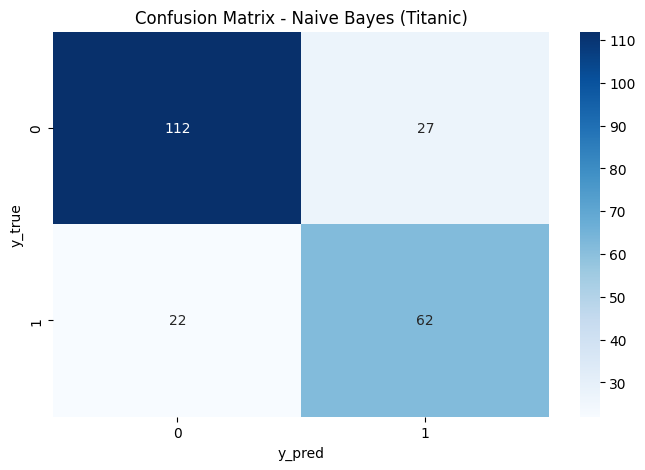

In [11]:
f, ax = plt.subplots(figsize=(8,5))
sns.heatmap(cm, annot=True, fmt=".0f", cmap='Blues', ax=ax)
plt.title('Confusion Matrix - Naive Bayes (Titanic)')
plt.xlabel("y_pred")
plt.ylabel("y_true")
plt.show()

## 10. Evaluasi: Accuracy & Classification Report

In [12]:
from sklearn.metrics import accuracy_score, classification_report
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=['Tidak Selamat (0)', 'Selamat (1)']))

Accuracy: 0.7803

                   precision    recall  f1-score   support

Tidak Selamat (0)       0.84      0.81      0.82       139
      Selamat (1)       0.70      0.74      0.72        84

         accuracy                           0.78       223
        macro avg       0.77      0.77      0.77       223
     weighted avg       0.78      0.78      0.78       223



## 11. Visualising the results (2 fitur: Age & Fare)
Visualisasi *decision boundary* hanya bisa digambar untuk 2 fitur. Maka dibuat model Naive Bayes terpisah yang hanya memakai **Age** dan **Fare** khusus untuk keperluan visualisasi (model utama di atas tetap memakai semua fitur).

Accuracy model 2 fitur (Age, Fare): 0.6951


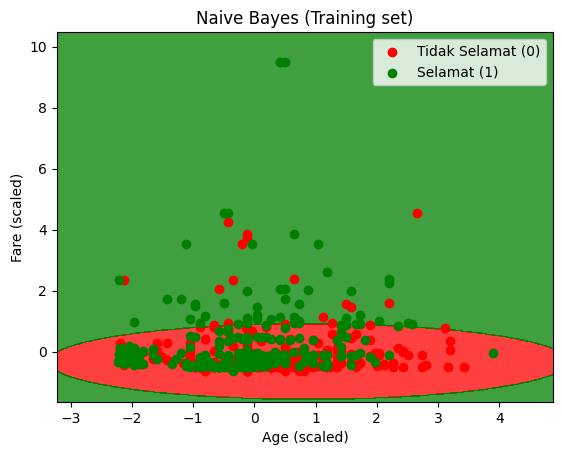

In [13]:
from matplotlib.colors import ListedColormap

# Ambil kolom Age & Fare saja
cols = list(data.drop(columns=['Survived']).columns)
idx = [cols.index('Age'), cols.index('Fare')]
X2 = data.drop(columns=['Survived']).values[:, idx]

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size = 0.25, random_state = 0)
sc2 = StandardScaler()
X2_train = sc2.fit_transform(X2_train)
X2_test = sc2.transform(X2_test)

clf2 = GaussianNB()
clf2.fit(X2_train, y2_train)
print('Accuracy model 2 fitur (Age, Fare):', round(clf2.score(X2_test, y2_test), 4))

def plot_boundary(X_set, y_set, judul):
    X1, X2g = np.meshgrid(np.arange(X_set[:, 0].min() - 1, X_set[:, 0].max() + 1, 0.02),
                          np.arange(X_set[:, 1].min() - 1, X_set[:, 1].max() + 1, 0.02))
    plt.contourf(X1, X2g, clf2.predict(np.array([X1.ravel(), X2g.ravel()]).T).reshape(X1.shape),
                 alpha = 0.75, cmap = ListedColormap(('red', 'green')))
    plt.xlim(X1.min(), X1.max())
    plt.ylim(X2g.min(), X2g.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                    color = ListedColormap(('red', 'green'))(i),
                    label = 'Tidak Selamat (0)' if j == 0 else 'Selamat (1)')
    plt.title(judul)
    plt.xlabel('Age (scaled)')
    plt.ylabel('Fare (scaled)')
    plt.legend()
    plt.show()

plot_boundary(X2_train, y2_train, 'Naive Bayes (Training set)')

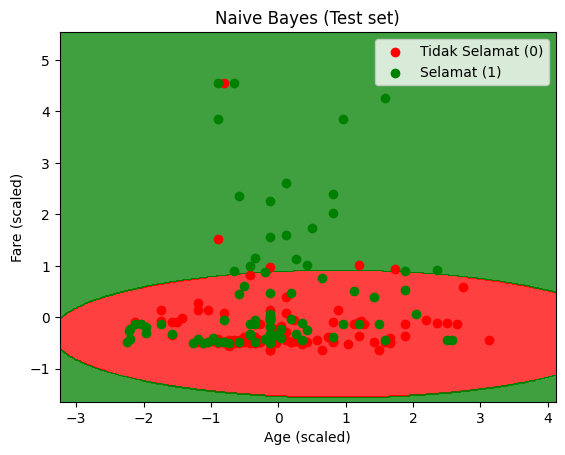

In [14]:
plot_boundary(X2_test, y2_test, 'Naive Bayes (Test set)')

## 12. Prediksi data baru (opsional)
Contoh: penumpang perempuan, kelas 1, umur 28, tanpa saudara/pasangan & orang tua/anak, tarif 100, naik dari Cherbourg.
Urutan fitur: `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked`

In [15]:
penumpang_baru = np.array([[1, 1, 28, 0, 0, 100, 1]])
hasil_baru = classifier.predict(sc.transform(penumpang_baru))
proba = classifier.predict_proba(sc.transform(penumpang_baru))
print('Prediksi:', 'SELAMAT' if hasil_baru[0] == 1 else 'TIDAK SELAMAT')
print('Probabilitas [Tidak Selamat, Selamat]:', proba.round(3))

Prediksi: SELAMAT
Probabilitas [Tidak Selamat, Selamat]: [[0.003 0.997]]


## 13. Kesimpulan
Model Gaussian Naive Bayes dilatih dengan data training (75%) dan diuji dengan data testing (25%). Hasil evaluasi (accuracy, precision, recall, f1-score) dan confusion matrix menunjukkan seberapa baik model memprediksi keselamatan penumpang Titanic. Fitur seperti **Sex** dan **Pclass** secara umum sangat berpengaruh terhadap peluang selamat.